https://www.kaggle.com/code/javidahamed/waste-classification-image-based                Refer this coding Part 

Data is saved in personal folder , hence below codes are commented

In [53]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")

# destination_path = r"C:\Users\ASUS\OneDrive\Ai-ML Data Science Guvi\Projects\Project 4 Image Classification"


# print("Path to dataset files:", path)

In [54]:
# The images which are downloded from Kaggle through above code has been manully saved into below folder and using the same folder to load the data
data = r"C:\Users\ASUS\OneDrive\Ai-ML Data Science Guvi\Projects\Project 4 Image Classification\Image Data\Garbage classification"

In [55]:
import os

jpg_count = 0

# Below code will count the files that ends with .jpg
for root, dirs, files in os.walk(data):
    for file in files:
        if file.lower().endswith(".jpg"):
            jpg_count += 1

print("Total JPG images:", jpg_count)

Total JPG images: 2527


In [56]:
# Inside the How many folder are there and checking the names as well
for item in os.listdir(data):
    path = os.path.join(data, item)

    if os.path.isdir(path):
        print(item)

cardboard
glass
metal
paper
plastic
trash


In [57]:
# Then Count Images Per Class
for cls in os.listdir(data):
    class_path = os.path.join(data, cls)

    if os.path.isdir(class_path):
        count = len([
            f for f in os.listdir(class_path)
            if f.endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{cls}: {count}")

cardboard: 403
glass: 501
metal: 410
paper: 594
plastic: 482
trash: 137


In [58]:
import pandas as pd

class_counts = {'cardboard': 403,
                'glass': 501,
                'metal': 410,
                'paper': 594,
                'plastic': 482,
                'trash': 137}

df = pd.DataFrame(list(class_counts.items()),columns=['Class', 'Count'])

df

,Class,Count
0,cardboard,403
1,glass,501
2,metal,410
3,paper,594
4,plastic,482
5,trash,137


Class Distribution Analysis
* The dataset contains six classes: cardboard, glass, metal, paper, plastic, and trash.
* Paper has the highest number of images (594).
* Trash has the lowest number of images (137).
* The dataset is imbalanced, particularly for the trash category.
* Data augmentation may be required during model training to improve generalization.

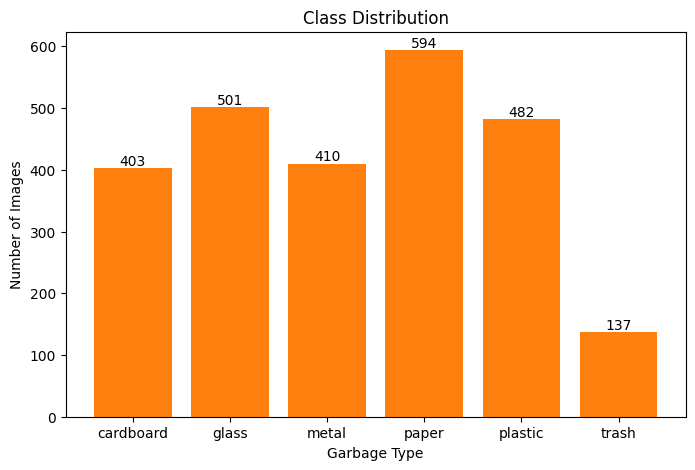

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
bars = plt.bar(df['Class'], df['Count'])
plt.bar(df['Class'], df['Count'])

plt.title('Class Distribution')
plt.xlabel('Garbage Type')
plt.ylabel('Number of Images')
plt.bar_label(bars)

plt.show()

Sample Image Analysis
* The dataset contains six waste categories: cardboard, glass, metal, paper, plastic, and trash.
* Sample images from each class were visualized successfully.
* Images have different object shapes and orientations.
* Most images contain a single dominant waste object.
* Backgrounds appear relatively consistent, which may help model training.

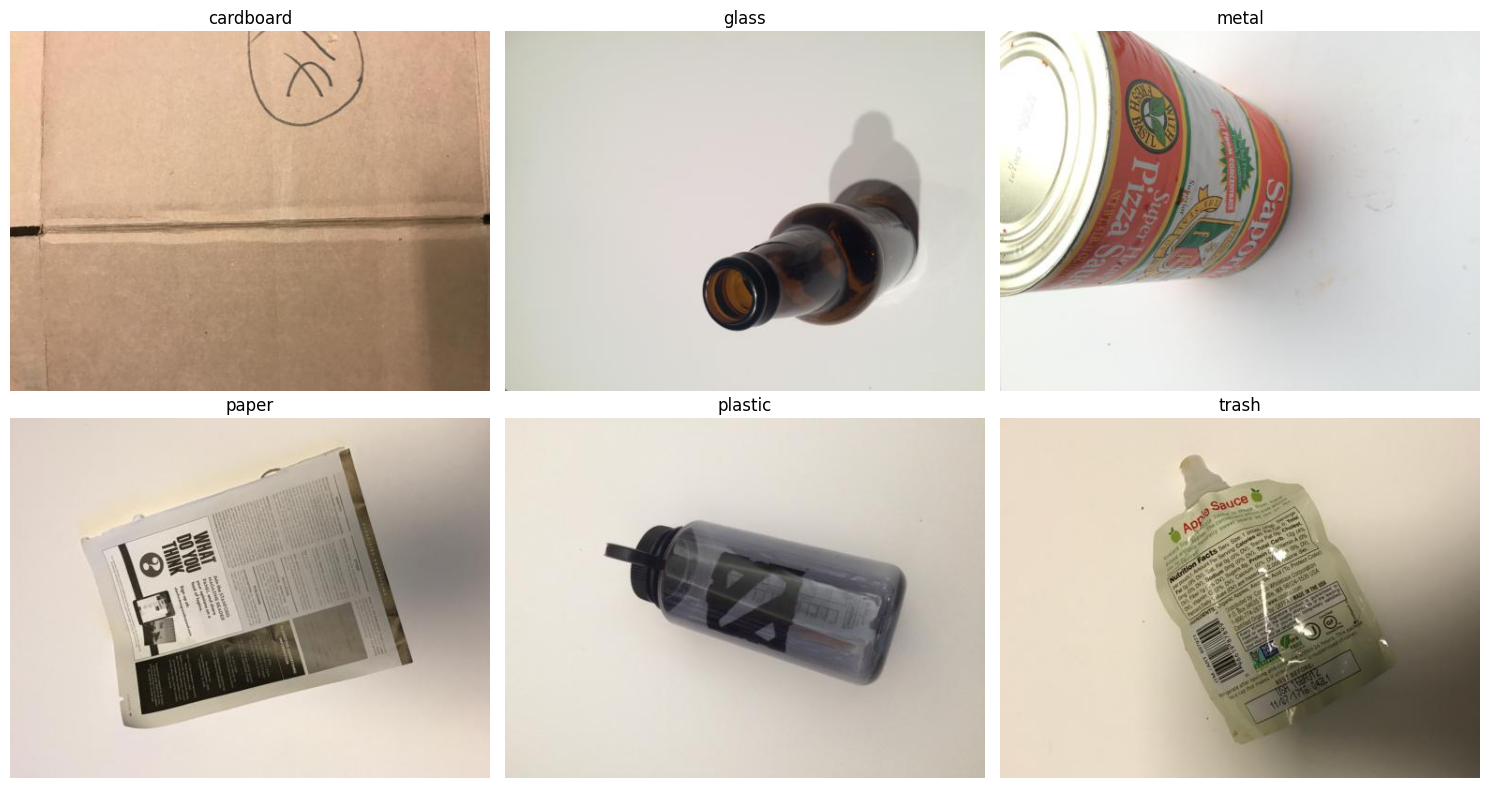

In [60]:
# Display one image from each catogries 

import matplotlib.pyplot as plt
from PIL import Image
import os

classes = os.listdir(data)

plt.figure(figsize=(15,8))

for i, cls in enumerate(classes):

    class_path = os.path.join(data, cls)

    image_file = os.listdir(class_path)[0]

    image_path = os.path.join(class_path, image_file)

    img = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.tight_layout()
plt.show()

Average Brightness Analysis
* The average pixel intensity distribution shows that most images fall between 160 and 185 intensity levels.
* The dataset appears reasonably well illuminated.
* No significant overexposure or underexposure was observed.
* Consistent lighting conditions are beneficial for model training.

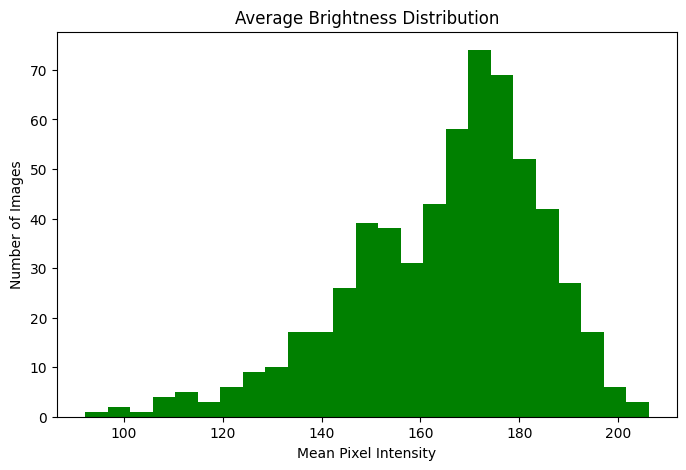

In [61]:
# ●	Analyze pixel intensity or color distribution.

from PIL import Image
import numpy as np
import os

mean_pixels = []

for cls in os.listdir(data):

    class_path = os.path.join(data, cls)

    if os.path.isdir(class_path):

        for img_file in os.listdir(class_path)[:100]:

            try:
                img = Image.open(
                    os.path.join(class_path, img_file)
                ).convert("L")

                mean_pixels.append(
                    np.array(img).mean()
                )

            except:
                pass

plt.figure(figsize=(8,5))

plt.hist(
    mean_pixels,
    bins=25,
    color="green"
)

plt.title("Average Brightness Distribution")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")

plt.show()

# 0 is no data in the pixel, which eaual to black, 255 is too brightness which is white, Balancing from 140 to 200 is considered as Balance Lighting

# Data Preprocessing

In [62]:
# ImageDataGenerator This is a built-in Keras tool which can:
# ✅ Read images
# ✅ Resize images
# ✅ Normalize images
# ✅ Augment images
# ✅ Create batches
# without us manually processing 2527 files.

from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, # Setting the width of the image  
            224) # Setting the hight of the image

BATCH_SIZE = 32 # Creating the Batch to send 32 images at a time instead of dumping all at one shot.

train_datagen = ImageDataGenerator(rescale=1./255, # Scalling the Pixel value from 0, 255 to 0,1
                                  rotation_range=20, #In real life users won't upload perfectly straight images, hence we do Bottle rotated 10°,Bottle rotated 15°,Bottle rotated 20°
                                  zoom_range=0.2, # People may take pictures from different distances. Bottle zoomed in and Bottle zoomed out
                                  horizontal_flip=True, # Bottle facing left and Bottle facing right
                                  validation_split=0.2) # 0.2 is 20% Validation and remaining 80% Training, 2527 × 0.8 ≈ 2021 and 2527 × 0.2 ≈ 506

✅ Resize to 224×224    *target_size=(224,224)
✅ Normalization *rescale=1./255
✅ Augmentation *rotation_range=20 *zoom_range=0.2 *horizontal_flip=True
✅ Training Split Created *subset='training'

In [63]:
# Creating the Training set, which is equal to x_train in ML

train_generator = train_datagen.flow_from_directory(data, # 2527 images are stored in in local drive and the local drive path is stored in "data"
    target_size=IMG_SIZE, # Predifined Normalizing image size 224,224 from above code
    batch_size=BATCH_SIZE, # Predifined Batch size from above code
    class_mode='categorical', # For multi-class classification we use:
    subset='training') # Now we're asking for:  Give me only the 80% training images.

# Expected Output :- Found 2024 images belonging to 6 classes.

Found 2024 images belonging to 6 classes.


In [64]:
# Creating the Test set, which is equal to x_test in ML

val_generator = train_datagen.flow_from_directory(data,
    target_size=IMG_SIZE, # Predifined Normalizing image size 224,224 from above code
    batch_size=BATCH_SIZE, # Predifined Batch size from above code
    class_mode='categorical', # For multi-class classification we use:
    subset='validation', # Now we're asking for:  Give me remining 20% training images.
    shuffle=False) # <--- CRITICAL: Keeps validation order fixed for accurate evaluation!

Found 503 images belonging to 6 classes.


Now we know
* Training Images   = 2024
* Validation Images = 503
* Classes           = 6

# Before Building a CNN
* Let's verify what TensorFlow is actually feeding into the model.
* This is a very important debugging step.
* Images => Correct ✅ 
* Labels => Wrong ❌

In [65]:
# Step 1: Check Class Labels
print(train_generator.class_indices)

{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


In [66]:
# Step 2: Inspect One Batch
images, labels = next(train_generator)

print(images.shape)

print(labels.shape)

# Expected out put is 32 images per batch, 224 width, 224 hight, 3 Dimensional images 
# The result should be (32,224,224,3)

(32, 224, 224, 3)
(32, 6)


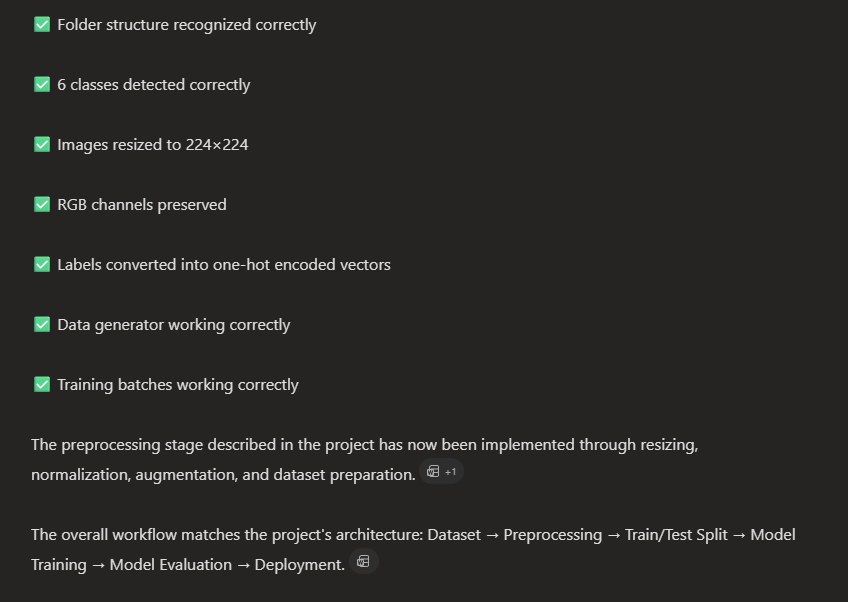

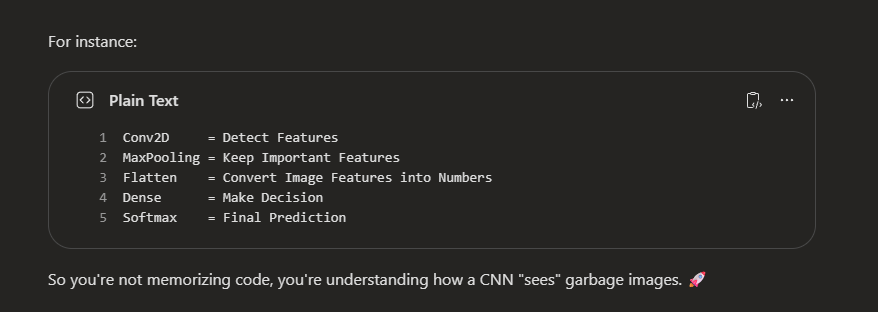

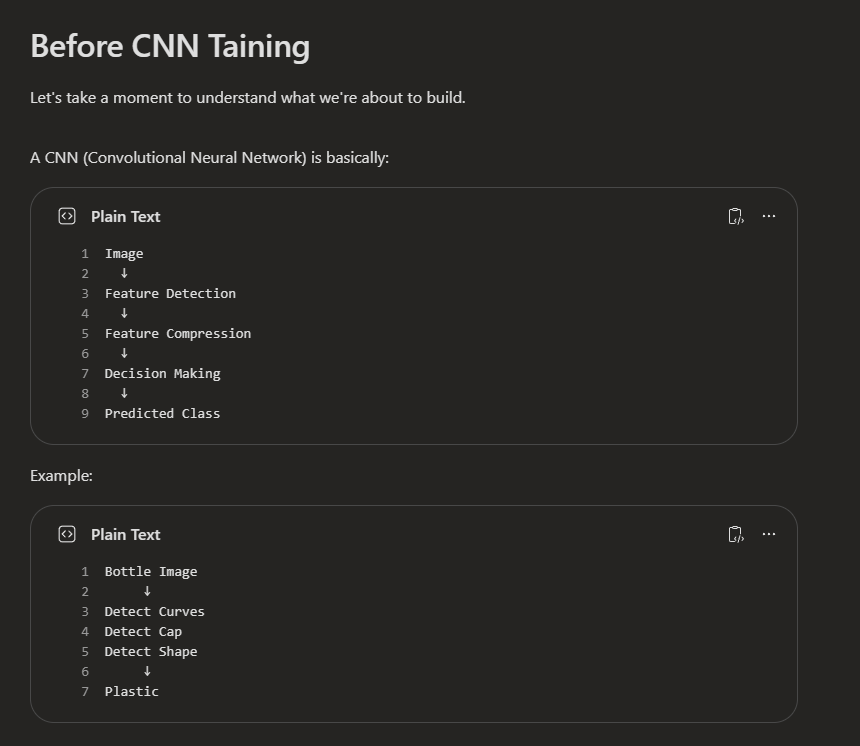

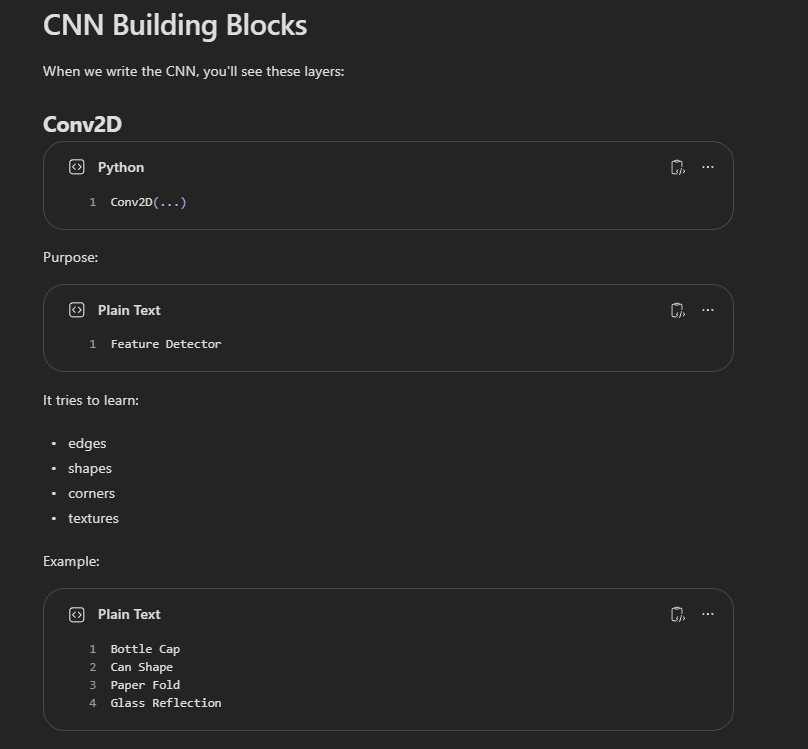

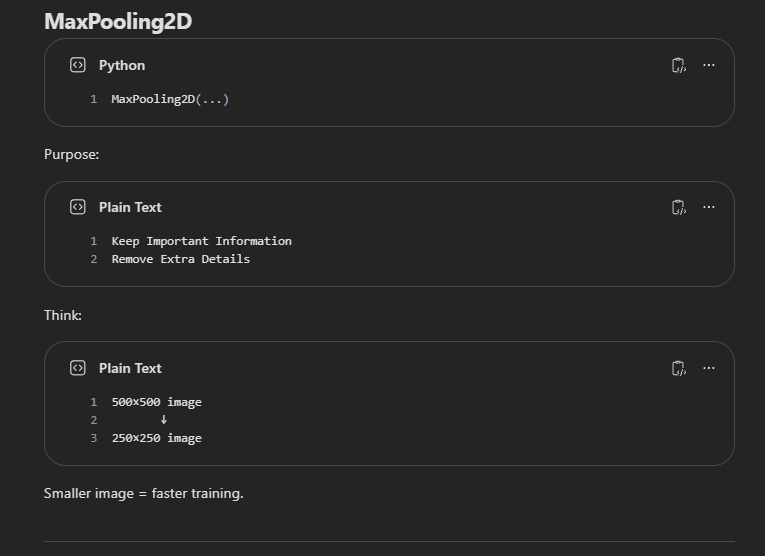

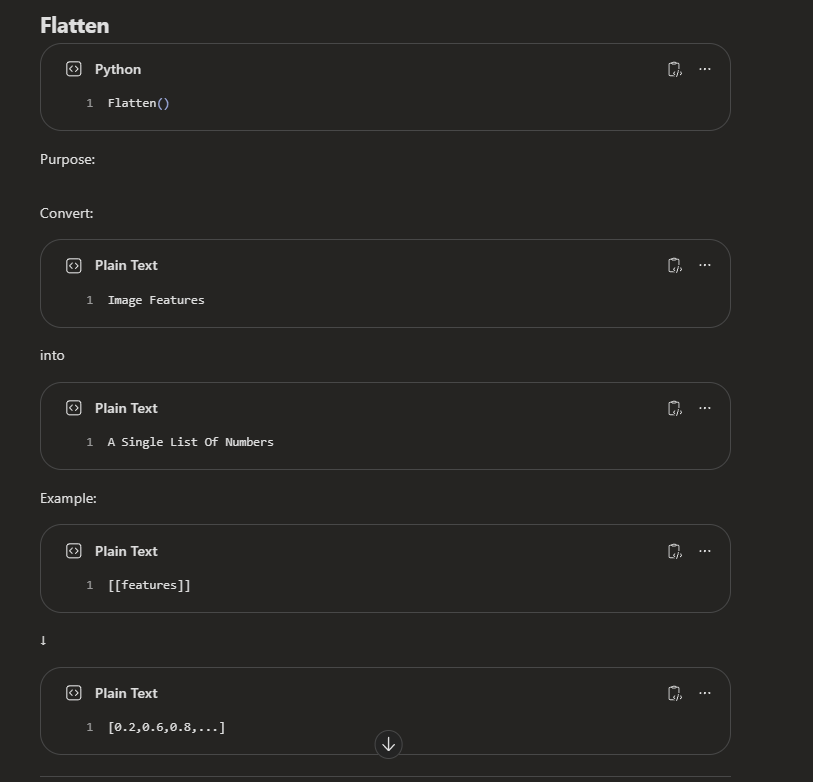

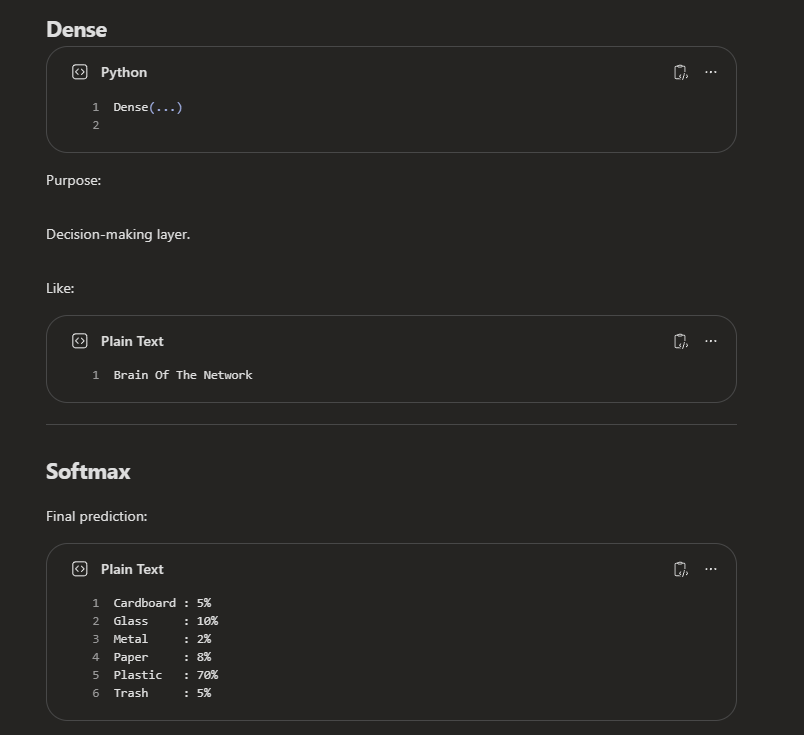

* CNN Architecture We Will Build

In [67]:
# Input Image (224x224x3)

# ↓
# Conv2D (32 filters)

# ↓
# MaxPooling

# ↓
# Conv2D (64 filters)

# ↓
# MaxPooling

# ↓
# Conv2D (128 filters)

# ↓
# MaxPooling

# ↓
# Flatten

# ↓
# Dense(128)

# ↓
# Dropout

# ↓
# Dense(6)

* Step 1: Import Required Layers

In [68]:

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

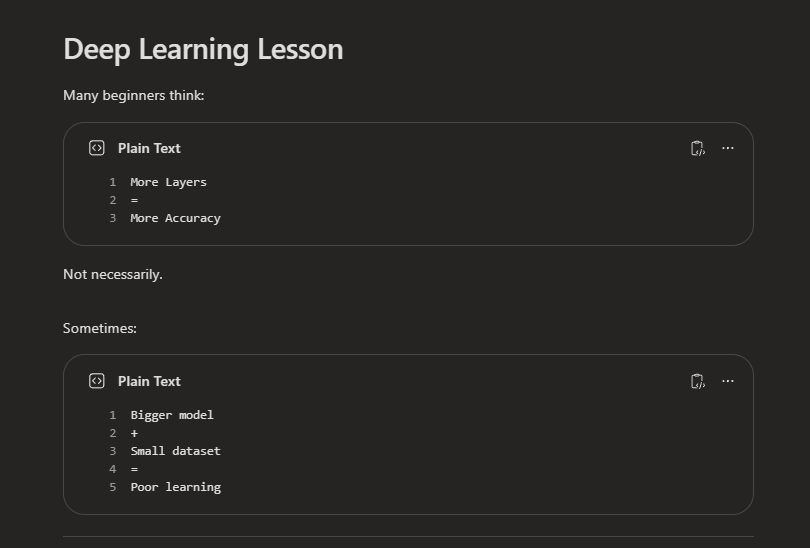

* Since the code was hyper tuned by myself by thinking Big Architechure , Big results, It was prooved wrong. Small data Small Architechure is fine.
* Hence I am turning below code to comment section and craeting small Arctitecture

* Step 2: Build the CNN

In [69]:
# # Our Mentor had explained the CNN concept using pytorch libraury , below is not from Pytorch, below is from tensor flow libraury 

# model = Sequential([
#     # First layer of CNN
#     Conv2D(32, # Starting with 32 filters, we can start with any number of filters like 8 or 16
#         (3,3), # Kernal size we are assigning as 3
#         activation='relu', # Activation function used Relu to keep learning only when the values are greater than 0. if less then 0 , Just dont go negative side
#         input_shape=(224,224,3)), #  Only at first layer we will give input

#     MaxPooling2D(2,2), # Cutting the Nurons by half way (2) and considering only max values from Nurons. This will help to run model fast. First 2 = Kernal size the other 2 = stred size

#     # Second layer of CNN
#     Conv2D(64,
#         (3,3),
#         activation='relu'),

#     MaxPooling2D(2,2),

#     # Third layer of CNN
#     Conv2D(128,
#         (3,3),
#         activation='relu'),

#     MaxPooling2D(2,2),

#     # Fourth layer of CNN
#     Conv2D(256,
#         (3,3),
#         activation='relu'),

#     MaxPooling2D(2,2),

#     # Flattening all feature maps into a single 1D vector
#     # CNN layers extract features in 3D format (height × width × channels).
#     # Dense layers cannot work with 3D data directly, so Flatten() converts
#     # the output into a single row of values that can be passed to the
#     # fully connected neural network for final classification.

#     Flatten(),  # Convert extracted CNN features into a 1D vector for the ANN part

#     # Fully Connected (Dense) Hidden Layer
#     # 128 neurons are used to learn complex patterns from the features
#     # extracted by the convolution layers. This layer combines all the
#     # important information learned by the CNN and helps make better
#     # classification decisions. ReLU activation introduces non-linearity
#     # and allows the model to learn more complex relationships.
#     # Input Shape: (26, 26, 128) After Flatten: 26 × 26 × 128 = 86,528 values Output Shape: (86528,)
#     # First layer of ANN
#     Dense(256, # Hidden layer with 256 neurons to learn high-level patterns from extracted features
#       activation='relu'),
#     Dropout(0.5),

#     # Second layer of ANN
#     Dense(128, # Hidden layer with 128 neurons to learn high-level patterns from extracted features
#       activation='relu'),
#     Dropout(0.5),

#     Dense(64, # Hidden layer with 64 neurons to learn high-level patterns from extracted features
#       activation='relu'),
#     Dropout(0.5),

#     Dense(6, # We are dealing with 6 classification hence we have used 6 here
#         activation='softmax')]) 

# # Relu is used to avoid minus results. If value < 0 → 0 Else → keep it
# # Most CNNs use ReLU.
# # Since we have given Dense as 6 , The softmax gives results as 6 scores, which ever class score is hight. we have to assume as models prediction

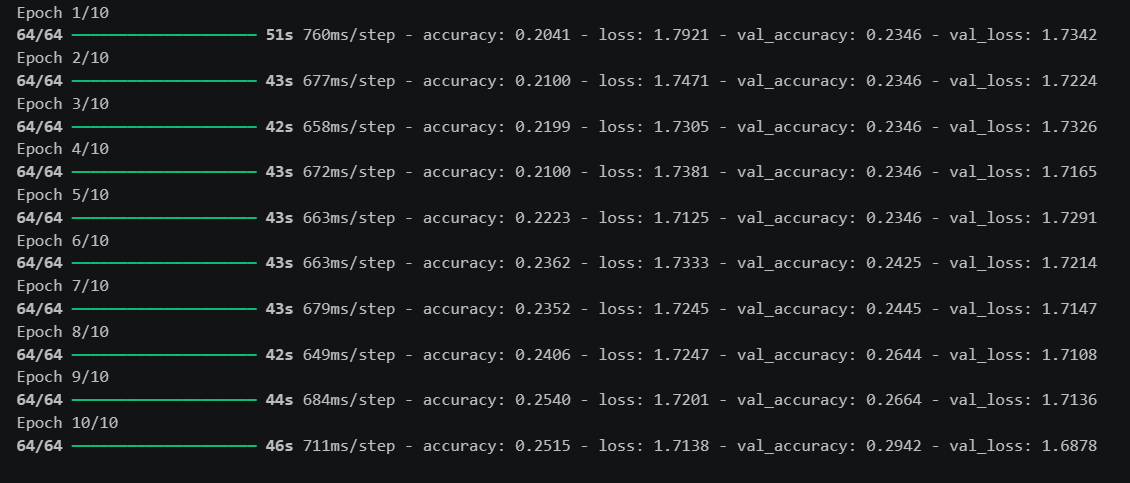

* The results are very Bad with above Architecture

In [70]:
# As discussed above, Building a small Architecture for small data to more accuracy

Model1 = Sequential([
                     # First layer of CNN
                    Conv2D(32, # # Starting with 32 filters, we can start with any number of filters like 8 or 16
                           (3,3), # Kernal size and stride we are assigning as 3
                           activation='relu', # Activation function used Relu to keep learning only when the values are greater than 0. if less then 0 , Just dont go negative side
                           input_shape = (224,224,3)), # Only at first layer we will give input
                           MaxPooling2D(2,2), # Cutting the Nurons by half way (2) and considering only max values from Nurons. This will help to run model fast. First 2 = Kernal size the other 2 = stred size
                     # Second layer of CNN
                    Conv2D(64,
                            (3,3),
                            activation='relu',),
                            MaxPooling2D(2,2),
                     # Third layer of CNN
                    Conv2D(128,
                           (3,3),
                           activation='relu'),
                           MaxPooling2D(2,2),

                    Flatten(), # Flattening the 3d layer to single vector to send the nurons to ANN Networks
                    # First layer of ANN
                    Dense(128,activation='relu'),
                    Dropout(0.5),
                    Dense(6,activation='softmax')                           
                           ])


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


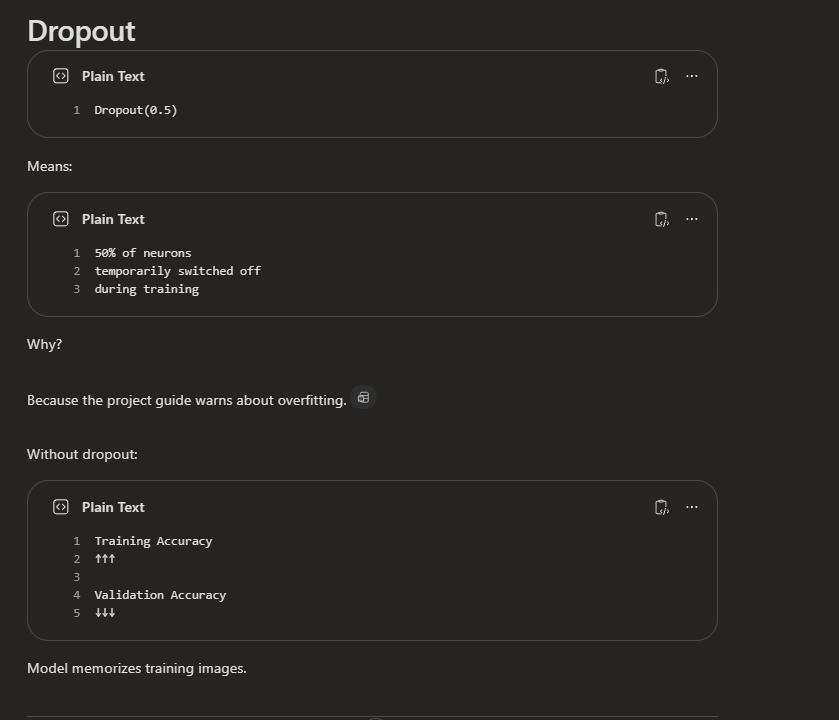

In [71]:
# print(model.summary())

* Next Step: Compile the Model

In [72]:
print(Model1.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

None


In [73]:
Model1.compile(optimizer='adam', # Adam Controls how weights are updated.
            loss='categorical_crossentropy',
            metrics=['accuracy'])

# Train the CNN

In [74]:
history = Model1.fit(
    train_generator, # Here we are passing the images which are stored for training
    validation_data=val_generator, # Here we are testing the images with Test set, like how accuratley the model has predicted
    epochs=10 # One batch = 32, we have given, Total training 2024. Hence 2024/32 = 64, So in each epochs 64 batches will be sent. 
    )

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 621ms/step - accuracy: 0.2920 - loss: 1.6497 - val_accuracy: 0.3698 - val_loss: 1.5167
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 625ms/step - accuracy: 0.4145 - loss: 1.4110 - val_accuracy: 0.4135 - val_loss: 1.4404
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 617ms/step - accuracy: 0.4857 - loss: 1.3047 - val_accuracy: 0.3777 - val_loss: 1.5386
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 623ms/step - accuracy: 0.4842 - loss: 1.2962 - val_accuracy: 0.4652 - val_loss: 1.3969
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 620ms/step - accuracy: 0.5435 - loss: 1.2026 - val_accuracy: 0.3976 - val_loss: 1.4540
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 623ms/step - accuracy: 0.5484 - loss: 1.1777 - val_accuracy: 0.4930 - val_loss: 1.3002
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 622ms/step - accuracy: 0.5726 - loss: 1.1083 - val_accuracy: 0.4652 - val_loss: 1.2765
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 624ms/step - accuracy: 0.5751 - loss: 1.0981 - val_accu

# Important Conclusion
* Our best epoch is probably: Epoch 9 not Epoch 10 , because: Validation Accuracy is higher at Epoch 9. 
* At Epoch 10 the Validation accuracy is reducing, which means the model is memorising and overfitting. 


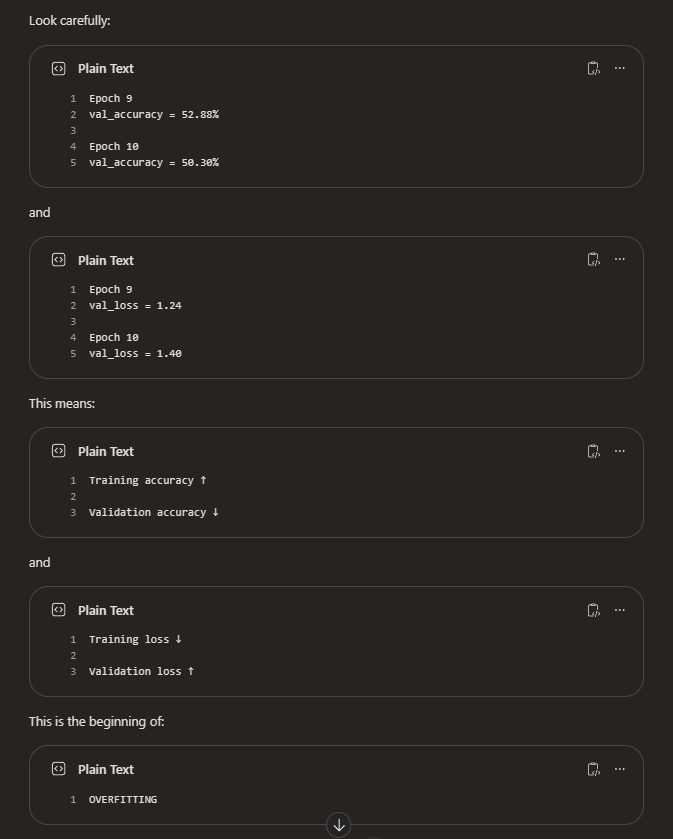

Baseline CNN Results
The baseline CNN model was trained for 10 epochs.

Training accuracy improved from 31.6% to 63.8%, indicating that the model successfully learned image features from the dataset.

Validation accuracy reached a maximum of 52.88% at Epoch 9.

A slight increase in validation loss during later epochs suggests the onset of overfitting.

The baseline CNN provides a useful benchmark, but its performance is below the project target. Transfer Learning will be explored to improve classification accuracy.

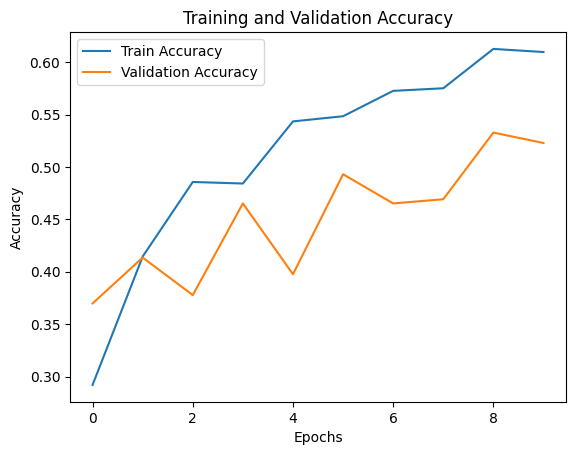

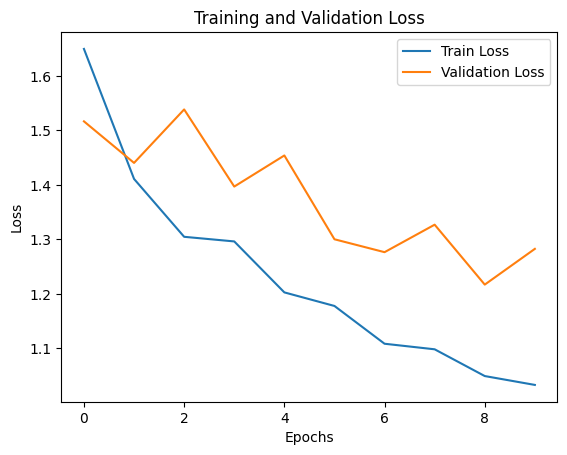

In [75]:
# Accuracy Plot
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss Plot
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Tranform 
* Step 1: Import MobileNetV2 ResNet50 EfficientNetB0

In [76]:
from tensorflow.keras.applications import MobileNetV2,ResNet50,EfficientNetB0 

from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.models import Model

In [77]:
# Step 1: Create the MobileNetV2 Base Model

base_mobilenet = MobileNetV2(
    weights='imagenet', # Don't start from scratch. Use knowledge learned from ImageNet.
    include_top=False, # MobileNetV2 originally ends with: 1000 ImageNet classes,  hence we are not incuding those. We need only 6 classes fo rour project
    input_shape=(224, 224, 3)
)

base_ResNet50 = ResNet50(
    weights='imagenet', # Don't start from scratch. Use knowledge learned from ImageNet.
    include_top=False, # ResNet50 originally ends with: 1000 ImageNet classes,  hence we are not incuding those. We need only 6 classes fo rour project
    input_shape=(224, 224, 3)
)

base_EfficientNetB0 = EfficientNetB0(
    weights='imagenet', # Don't start from scratch. Use knowledge learned from ImageNet.
    include_top=False, # EfficientNetB0 originally ends with: 1000 ImageNet classes,  hence we are not incuding those. We need only 6 classes fo rour project
    input_shape=(224, 224, 3)
)

In [78]:
# Step 2: Freeze the Base Model
base_mobilenet.trainable = False
base_ResNet50.trainable = False
base_EfficientNetB0.trainable = False

# Why freeze?
# Think of MobileNetV2 as an expert teacher.
# It already knows:
# Plain Text
# Edges
# Shapes
# Patterns
# Textures
# We don't want to erase that knowledge.

print(base_mobilenet.trainable)
print(base_ResNet50.trainable)
print(base_EfficientNetB0.trainable)


False
False
False


# Creating the layers for Mobilenet

In [79]:
# MobileNetV2 extracts image features
x = base_mobilenet.output # starts by holding the raw feature maps extracted from your MobileNetV2 base model.

# Compress features
x = GlobalAveragePooling2D()(x) # It takes whatever is currently stored in x, passes it through the pooling layer, and stores the transformed result right back into x

# Custom classifier , The last layer of ANN whcih we have trained
# Add a fully connected Dense layer with 128 neurons and ReLU activation to learn task-specific patterns
x = Dense(128, activation='relu')(x) # It takes the updated tensor in x, passes it through the Dense layer, and updates x.

# Prevent overfitting by dropping out 0.5% nurons
# Randomly drop 50% of active connections during training to prevent the model from overfitting
x = Dropout(0.5)(x) # It applies dropout to x and updates x again.

# Predict cardboard, glass, metal, paper, plastic, or trash
predictions = Dense(6, activation='softmax')(x) # Finally, it takes the fully processed tensor x and passes it into your final classification layer to get your 6 class probabilities.

# Create the final Transfer Learning model by combining:
# 1. The pretrained MobileNetV2 feature extractor
# 2. The custom classification layers added on top
#
# MobileNetV2 is responsible for extracting useful image features
# such as edges, shapes, textures, and object patterns learned
# from millions of images during ImageNet training.
#
# The custom classification head uses these extracted features
# to classify the input image into one of the six garbage categories:
# cardboard, glass, metal, paper, plastic, and trash.
#
# This approach is called Transfer Learning, where a pretrained
# model is reused instead of training a deep network from scratch,
# resulting in faster training and better accuracy on smaller datasets.
mobilenet_model = Model(
    inputs=base_mobilenet.input,      # Input image enters through MobileNetV2 # Define the model's input tensor (raw images enter through the MobileNetV2 base)
    outputs=predictions          # Final prediction of one of the 6 classes # Define the model's final output tensor (predicted probabilities across your 6 classes)
)

# Use MobileNetV2 to extract image features and add a custom classifier to predict the 6 garbage categories.

# Creating the layers for ResNet50
* Since x varaible is already used in above , using "y" here 

In [80]:
y = base_ResNet50.output         # Take the output feature maps from the ResNet50 base model

y = GlobalAveragePooling2D()(y) # Convert 2D feature maps into a 1D vector by calculating the average for each feature map

y = Dense(128, activation='relu')(y) # Add a fully connected Dense layer with 128 neurons and ReLU activation to learn task-specific patterns

y = Dropout(0.5)(y)           # Randomly drop 50% of active connections during training to prevent the model from overfitting

predictions = Dense(6, activation='softmax')(y) # Final output layer with 6 neurons (one for each garbage class) using softmax to output probabilities

# Step 4: Assemble the Complete Model
resnet_model = Model(
    inputs=base_ResNet50.input,    # Define the model's input tensor (raw images enter through the ResNet50 base)
    outputs=predictions)        # Define the model's final output tensor (predicted probabilities across your 6 classes)

# Step 5: Compile the Model
resnet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'])

# Creating the layers for base_EfficientNetB0
* Since x & y varaible is already used in above , using "z" here 

In [81]:
z = base_EfficientNetB0.output         # Take the output feature maps from the ResNet50 base model

z = GlobalAveragePooling2D()(z) # Convert 2D feature maps into a 1D vector by calculating the average for each feature map

z = Dense(128, activation='relu')(z) # Add a fully connected Dense layer with 128 neurons and ReLU activation to learn task-specific patterns

z = Dropout(0.5)(z)           # Randomly drop 50% of active connections during training to prevent the model from overfitting

predictions = Dense(6, activation='softmax')(z) # Final output layer with 6 neurons (one for each garbage class) using softmax to output probabilities

# Step 4: Assemble the Complete Model
EfficientNetB0_model = Model(
    inputs=base_EfficientNetB0.input,    # Define the model's input tensor (raw images enter through the ResNet50 base)
    outputs=predictions)        # Define the model's final output tensor (predicted probabilities across your 6 classes)

# Step 5: Compile the Model
EfficientNetB0_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'])

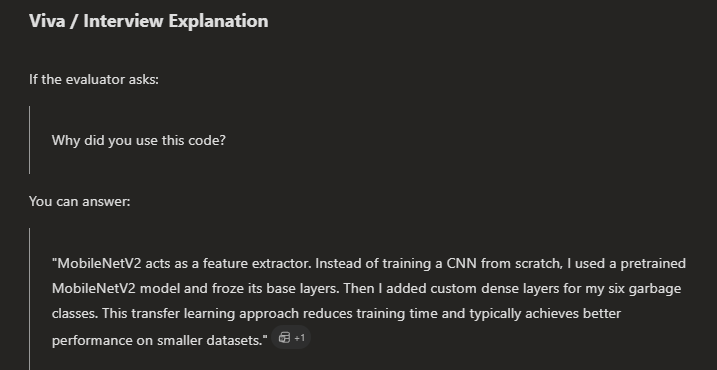

In [82]:
mobilenet_model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [83]:
# Configure how the model learns and measures performance
mobilenet_model.compile(
    optimizer='adam', # Optimization algorithm
    loss='categorical_crossentropy', # Loss function for multi-class classification
    metrics=['accuracy'] # Track accuracy during training
)

In [84]:
# Configure how the model learns and measures performance
resnet_model.compile(
    optimizer='adam', # Optimization algorithm
    loss='categorical_crossentropy', # Loss function for multi-class classification
    metrics=['accuracy'] # Track accuracy during training
)

In [85]:
# Configure how the model learns and measures performance
EfficientNetB0_model.compile(
    optimizer='adam', # Optimization algorithm
    loss='categorical_crossentropy', # Loss function for multi-class classification
    metrics=['accuracy'] # Track accuracy during training
)

In [86]:
mobilenet_model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Next Step After Compile

In [87]:
# Train MobileNetV2 using training images
# Evaluate after each epoch using validation images

print('Started Training with MobileNetV2')
# Train MobileNetV2 using training images
history_mobilenet = mobilenet_model.fit(
    train_generator, # Our 80% Images set for Training 
    validation_data=val_generator, # Our 20% Images set for validation 
    epochs=10)

print('Started Training with resnet')
# Train resnet using training images
history_resnet = resnet_model.fit(
    train_generator, # Our 80% Images set for Training 
    validation_data=val_generator, # Our 20% Images set for validation 
    epochs=10)

print('Started Training with EfficientNetB0')
# Train EfficientNetB0 using training images
history_EfficientNetB0 = EfficientNetB0_model.fit(
    train_generator, # Our 80% Images set for Training 
    validation_data=val_generator, # Our 20% Images set for validation 
    epochs=10)

Started Training with MobileNetV2
Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 46s 658ms/step - accuracy: 0.5795 - loss: 1.1481 - val_accuracy: 0.6481 - val_loss: 0.9038
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 644ms/step - accuracy: 0.7406 - loss: 0.7044 - val_accuracy: 0.6978 - val_loss: 0.7647
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 629ms/step - accuracy: 0.7925 - loss: 0.5900 - val_accuracy: 0.6998 - val_loss: 0.7704
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 627ms/step - accuracy: 0.8083 - loss: 0.5568 - val_accuracy: 0.6958 - val_loss: 0.7694
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 43s 669ms/step - accuracy: 0.8177 - loss: 0.4927 - val_accuracy: 0.7117 - val_loss: 0.7429
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 635ms/step - accuracy: 0.8271 - loss: 0.4641 - val_accuracy: 0.7237 - val_loss: 0.7284
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 635ms/step - accuracy: 0.8305 - loss: 0.4532 - val_accuracy: 0.7396 - val_loss: 0.7060
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 637ms/step - accuracy

MobileNetV2 Transfer Learning Results
A pretrained MobileNetV2 model was used as a feature extractor, and custom classification layers were added for six waste classes.

The model achieved:

Training Accuracy: 86.9%
Validation Accuracy: 75.5%
Compared to the baseline CNN, the MobileNetV2 model showed significant improvement in both convergence speed and accuracy.

Transfer learning enabled the model to leverage features learned from large-scale image datasets, resulting in better generalization on unseen garbage images.

📊 Training Performance Breakdown
* Training Accuracy & Loss: Your training accuracy steadily climbed from 56.7% up to an impressive 87.2%, while training loss dropped significantly from 1.128 down to 0.343. This shows the custom classification head is learning the features of your 6 garbage classes effectively.

* Validation Accuracy & Loss: Your validation accuracy started high at 68.2% and peaked at 76.5% (achieved at Epoch 8 and Epoch 10). Validation loss also trended downwards, settling around 0.63 – 0.64.

 * Stability: While there are minor fluctuations in validation accuracy between epochs (which is completely normal due to batch variations and the smaller validation split), the model is showing solid generalization without severe overfitting.

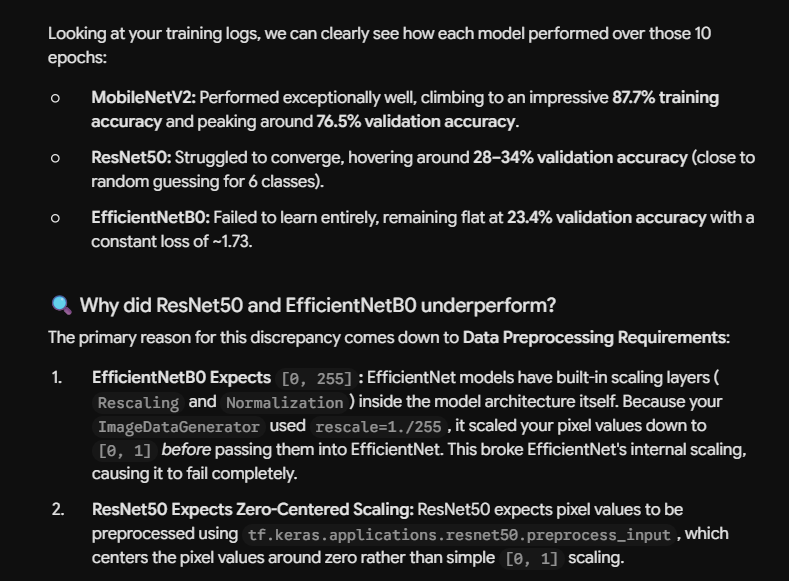

# Model Evaluation & Confusion Matrix

16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 562ms/step
Classification Report:

              precision    recall  f1-score   support

   cardboard       1.00      0.76      0.87        80
       glass       0.66      0.82      0.73       100
       metal       0.77      0.79      0.78        82
       paper       0.81      0.93      0.87       118
     plastic       0.73      0.65      0.69        96
       trash       0.54      0.26      0.35        27

    accuracy                           0.77       503
   macro avg       0.75      0.70      0.71       503
weighted avg       0.77      0.77      0.76       503



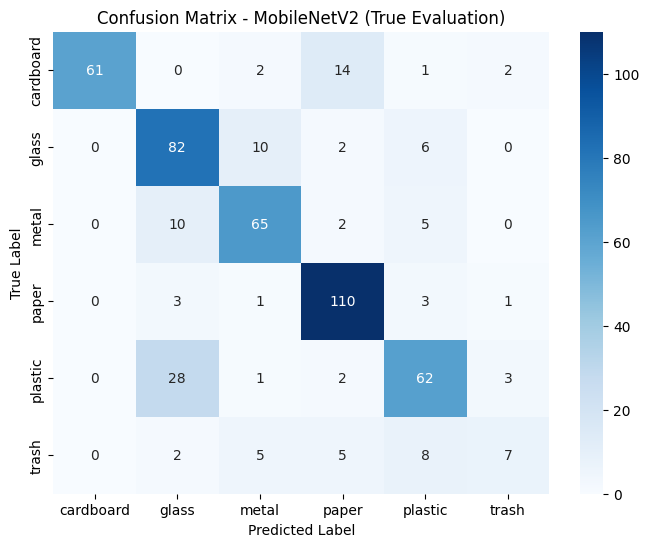

In [88]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Predict on the ordered validation generator
val_generator.reset()
Y_pred = mobilenet_model.predict(val_generator)
y_pred = np.argmax(Y_pred, axis=1)

# 2. Get true labels directly and reliably (since shuffle=False keeps them aligned)
y_true = val_generator.classes

# Get class labels from your generator mapping
class_labels = list(val_generator.class_indices.keys())

# 3. Print Classification Report (Precision, Recall, F1-Score per class)
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))

# 4. Generate and Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix - MobileNetV2 (True Evaluation)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [89]:
# To save your model
mobilenet_model.save("garbage_classifier_model.keras") 
# (or .h5 format as used in your earlier code)

# To load your model later in Streamlit
from tensorflow.keras.models import load_model
model = load_model("garbage_classifier_model.keras")